# Conformal Prediction: ejemplo computacional

**Curso:** Aprendizaje Automático, MCDA 2026-2, Universidad EAFIT · **Profesor:** Andrés Vásquez Restrepo
**Tema de exposición:** Conformal Prediction (línea Sistemas) · **Expositor:** Pedro Villegas Michel

---

**Objetivo:** mostrar, paso a paso, cómo convertir un modelo **XGBoost** en uno que entrega **intervalos** (regresión)
o **conjuntos de etiquetas** (clasificación) con una **garantía de cobertura**:

$$P\big(Y_{nuevo} \in C(X_{nuevo})\big) \ge 1 - \alpha$$

Se trabajan **tres métodos**:

| Método | Idea | Dónde se usa aquí |
|---|---|---|
| **1. Split conformal** (banda fija) | un solo umbral $\hat q$ para todos los casos | Parte A (regresión) y Parte B (fraude) |
| **2. CQR** (banda adaptativa) | regresión cuantílica corregida con $\hat q$ | Parte A |
| **3. Mondrian** (umbral por clase) | un $\hat q$ distinto para cada clase | Parte B: **garantía de recall** en fraude |

| Parte | Qué se muestra | Datos |
|---|---|---|
| **A** | Regresión: banda fija frente a CQR, con `XGBRegressor` | Sintéticos, ruido que crece con x |
| **B** | Fraude con `XGBClassifier` (parámetros del notebook 02), evaluado con **recall, precisión y matriz de confusión** | Kaggle `kartik2112/fraud-detection` |
| **C** | ¿Cuántos datos de calibración se necesitan? | Teoría (distribución Beta) + simulación |
| **D** | Los mismos métodos con la librería **MAPIE** | Los de A y B |

**Tiempo de ejecución:** alrededor de 30 segundos con los datos ya descargados. Semilla 42: los números coinciden con la presentación.

## La idea en palabras sencillas: el empleado nuevo

Un empleado nuevo estima el valor de las facturas a simple vista. Para saber cuánto confiar en él:

1. Le muestro **100 facturas cuyo valor real ya conozco** y que él nunca ha visto.
2. Anoto **cuánto se equivocó** en cada una.
3. Ordeno los errores de menor a mayor y miro el **error número 90** (digamos, 80 mil pesos).
4. Desde hoy, si dice “vale 1 millón”, yo digo **“entre 920 mil y 1.080.000”**, y acierto el 90 % de las veces.

| En la analogía | En este notebook |
|---|---|
| El empleado | El modelo (XGBoost) |
| Las 100 facturas | El set de **calibración** |
| Cuánto se equivocó | El **score** (error) |
| El error número 90 | **q̂** (`q_hat`), el umbral |
| El 90 % | **1 − α** (α es el error que acepto) |

No hace falta saber cómo piensa el empleado: solo medimos sus errores en casos que no había visto. **Eso es conformal prediction.**

## 0. Cómo ejecutar

- **Local:** `pip install numpy pandas scipy scikit-learn matplotlib xgboost kagglehub mapie` y *Run All*
  (MAPIE solo se usa en la Parte D; si falta, esa celda lo avisa).
- **Datos:** la celda B.1 busca `fraudTrain.csv` y `fraudTest.csv` en `data/`, `../data/` o la caché de `kagglehub`; si no los encuentra, los descarga (dataset público).
  Si Kaggle pide autenticación, descárguelos a mano y déjelos en `data/`.
- `SAVE_FIGURES = True` regenera las figuras de la presentación en `figuras/`.

In [1]:
# =============================================================================
# 0.1 Imports y configuración
# =============================================================================
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore", message="X does not have valid feature names")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)   # generador único: el orden de uso importa para reproducir
SAVE_FIGURES = False
FIG_DIR = Path("figuras")
if SAVE_FIGURES:
    FIG_DIR.mkdir(exist_ok=True)

# Paleta de la presentación (colores accesibles para daltonismo)
BLUE, ORANGE, AQUA, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#e34948"
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")


def save(name: str) -> None:
    if SAVE_FIGURES:
        plt.savefig(FIG_DIR / name, dpi=200)

## 1. La pieza central: el cuantil conformal

Los tres métodos usan **la misma función**. Dados los *scores de no conformidad* de calibración $s_1,\dots,s_n$
(qué tan “mal” le fue al modelo con cada punto), se toma

$$\hat q = s_{(k)}, \qquad k = \lceil (n+1)(1-\alpha) \rceil$$

es decir, el $k$-ésimo score más pequeño. El **“+1”** cuenta al punto nuevo dentro del ranking: es lo que hace
que la garantía valga con muestras finitas. Si $k > n$ (muy pocos datos para el α pedido), $\hat q = \infty$.

In [2]:
# =============================================================================
# 1.1 Cuantil conformal con corrección de muestra finita
# =============================================================================
def conformal_quantile(scores: np.ndarray, alpha: float) -> float:
    # Devuelve el ceil((n+1)(1-alpha))-ésimo score más pequeño.
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    if k > n:
        return np.inf                      # muy pocos datos: el conjunto es "todo"
    return float(np.sort(scores)[k - 1])


# Mini ejemplo para entender: 9 scores de calibración y alpha = 0.2
toy = np.array([0.3, 1.2, 0.7, 2.5, 0.1, 0.9, 1.8, 0.4, 3.1])
k = int(np.ceil((len(toy) + 1) * (1 - 0.2)))
print("scores ordenados:", np.sort(toy))
print(f"n = {len(toy)}, k = ceil(10 * 0.8) = {k}  ->  q_hat = {conformal_quantile(toy, 0.2)}")
print("Un punto nuevo queda 'cubierto' si su score es <= q_hat: pasa en al menos el 80 % de los casos.")

scores ordenados: [0.1 0.3 0.4 0.7 0.9 1.2 1.8 2.5 3.1]
n = 9, k = ceil(10 * 0.8) = 8  ->  q_hat = 2.5
Un punto nuevo queda 'cubierto' si su score es <= q_hat: pasa en al menos el 80 % de los casos.


---
# Parte A. Regresión: método 1 (banda fija) y método 2 (CQR)

Simulamos $y = x \sin(x) + \varepsilon$, donde el ruido **crece con $x$** (desviación de 0,15 a 3,65).
Es el caso donde un intervalo de ancho fijo sufre: sobra en la zona tranquila y falta en la ruidosa.

Separación en **tres partes**: entrenamiento (1.500), **calibración** (750) y prueba (750).
La calibración **nunca** se usa para entrenar: si se usara, la garantía se rompe.

In [3]:
# =============================================================================
# A.1 Datos sintéticos y separación train / calibración / test
# =============================================================================
ALPHA = 0.10                                   # queremos cobertura del 90 %
n = 3000
x = rng.uniform(0, 10, n)
y = x * np.sin(x) + rng.normal(0, 0.15 + 0.35 * x)   # el ruido crece con x
X = x.reshape(-1, 1)
idx = rng.permutation(n)
tr, cal, te = idx[:1500], idx[1500:2250], idx[2250:]
print(f"train {len(tr)} | calibración {len(cal)} | test {len(te)}")

train 1500 | calibración 750 | test 750


### A.2 Método 1: split conformal (banda fija)

1. Entrenar **cualquier** modelo de regresión (aquí `XGBRegressor`) con *train*.
2. Score de calibración: $s_i = |y_i - \hat y(x_i)|$.
3. $\hat q$ = cuantil conformal de esos scores.
4. Intervalo para un punto nuevo: $[\hat y(x) - \hat q,\; \hat y(x) + \hat q]$ — **el mismo ancho para todos**.

In [4]:
# =============================================================================
# A.2 Split conformal: XGBoost para la media + residuo absoluto
# =============================================================================
XGB_REG = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=20, random_state=RANDOM_STATE)
mean_model = XGBRegressor(**XGB_REG).fit(X[tr], y[tr])       # paso 1

scores_cal = np.abs(y[cal] - mean_model.predict(X[cal]))     # paso 2
q_hat = conformal_quantile(scores_cal, ALPHA)                 # paso 3

pred_te = mean_model.predict(X[te])                           # paso 4
cov_split = np.mean(np.abs(y[te] - pred_te) <= q_hat)
print(f"q_hat = {q_hat:.3f} -> intervalo = prediccion ± {q_hat:.2f} (ancho {2 * q_hat:.2f})")
print(f"Cobertura en test: {cov_split:.1%} (objetivo {1 - ALPHA:.0%})")

q_hat = 3.778 -> intervalo = prediccion ± 3.78 (ancho 7.56)
Cobertura en test: 91.5% (objetivo 90%)


### A.3 Método 2: CQR, Conformalized Quantile Regression (Romano et al., 2019)

1. Entrenar **dos** XGBoost cuantílicos (`objective="reg:quantileerror"`): uno para el cuantil 5 % y otro para el 95 %. Ya dan una banda adaptativa, pero **sin garantía**.
2. Score: $s_i = \max\big(\hat q_{bajo}(x_i) - y_i,\; y_i - \hat q_{alto}(x_i)\big)$: cuánto se sale el punto de la banda (negativo si está adentro).
3. Intervalo final: $[\hat q_{bajo}(x) - \hat q,\; \hat q_{alto}(x) + \hat q]$. El paso conformal **corrige** la banda: la ensancha si cubría de menos y la **estrecha** si cubría de más.

In [5]:
# =============================================================================
# A.3 CQR: XGBoost cuantílico + calibración conformal
# =============================================================================
lo_m = XGBRegressor(objective="reg:quantileerror", quantile_alpha=ALPHA / 2, **XGB_REG).fit(X[tr], y[tr])
hi_m = XGBRegressor(objective="reg:quantileerror", quantile_alpha=1 - ALPHA / 2, **XGB_REG).fit(X[tr], y[tr])

cqr_scores = np.maximum(lo_m.predict(X[cal]) - y[cal], y[cal] - hi_m.predict(X[cal]))
q_cqr = conformal_quantile(cqr_scores, ALPHA)

lo_te, hi_te = lo_m.predict(X[te]) - q_cqr, hi_m.predict(X[te]) + q_cqr
cov_cqr = np.mean((y[te] >= lo_te) & (y[te] <= hi_te))

raw_cov = np.mean((y[te] >= lo_m.predict(X[te])) & (y[te] <= hi_m.predict(X[te])))
print(f"Banda cuantílica SIN calibrar: cobertura {raw_cov:.1%}  <- sin garantía (aquí cubre de más)")
print(f"CQR (q_hat = {q_cqr:+.3f}, la banda se estrecha): cobertura {cov_cqr:.1%}, ancho medio {np.mean(hi_te - lo_te):.2f}")
print(f"Split conformal:                          cobertura {cov_split:.1%}, ancho {2 * q_hat:.2f}")

Banda cuantílica SIN calibrar: cobertura 92.5%  <- sin garantía (aquí cubre de más)
CQR (q_hat = -0.243, la banda se estrecha): cobertura 90.4%, ancho medio 6.61
Split conformal:                          cobertura 91.5%, ancho 7.56


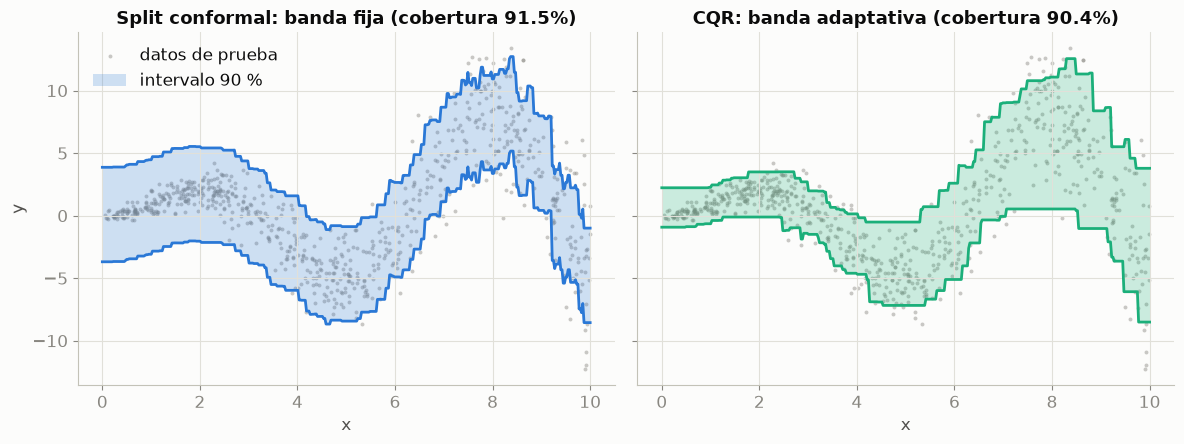

In [6]:
# =============================================================================
# A.4 Figura: banda fija frente a banda adaptativa
# =============================================================================
grid = np.linspace(0, 10, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, title, lo, hi, color in [
    (axes[0], f"Split conformal: banda fija (cobertura {cov_split:.1%})",
     mean_model.predict(grid) - q_hat, mean_model.predict(grid) + q_hat, BLUE),
    (axes[1], f"CQR: banda adaptativa (cobertura {cov_cqr:.1%})",
     lo_m.predict(grid) - q_cqr, hi_m.predict(grid) + q_cqr, AQUA),
]:
    ax.scatter(x[te], y[te], s=8, color=MUTED, alpha=0.45, linewidths=0, label="datos de prueba")
    ax.fill_between(grid.ravel(), lo, hi, color=color, alpha=0.22, linewidth=0, label="intervalo 90 %")
    ax.plot(grid, lo, color=color, lw=2)
    ax.plot(grid, hi, color=color, lw=2)
    ax.set(title=title, xlabel="x")
axes[0].set_ylabel("y")
axes[0].legend(loc="upper left")
plt.tight_layout()
save("a_regresion_split_vs_cqr.png")
plt.show()

### A.5 La advertencia clave: la garantía es **marginal** (promedio), no por zona

Medimos la cobertura por tramos de $x$. La banda fija “cumple” el 90 % global **sobrecubriendo** donde hay poco ruido
y **subcubriendo** donde hay mucho. CQR reparte la cobertura de forma más pareja.

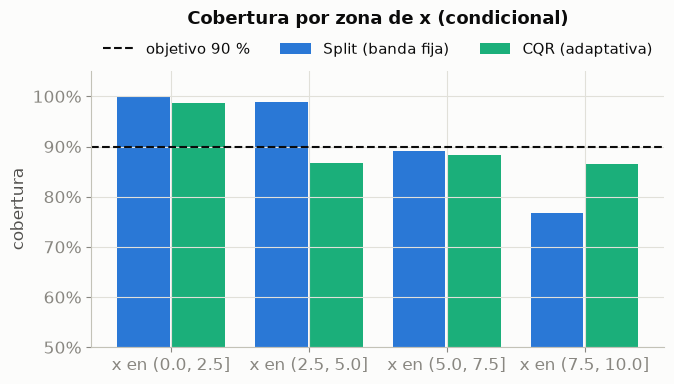

,split,cqr
zona,,
"(0.0, 2.5]",100.0%,98.6%
"(2.5, 5.0]",98.9%,86.6%
"(5.0, 7.5]",89.0%,88.4%
"(7.5, 10.0]",76.7%,86.5%


In [7]:
# =============================================================================
# A.5 Cobertura condicional por zona de x
# =============================================================================
cond = pd.DataFrame({
    "zona": pd.cut(x[te], [0, 2.5, 5, 7.5, 10]),
    "split": np.abs(y[te] - pred_te) <= q_hat,
    "cqr": (y[te] >= lo_te) & (y[te] <= hi_te),
}).groupby("zona", observed=True)[["split", "cqr"]].mean()

fig, ax = plt.subplots(figsize=(7, 4))
pos = np.arange(len(cond))
ax.bar(pos - 0.2, cond["split"], 0.38, color=BLUE, label="Split (banda fija)")
ax.bar(pos + 0.2, cond["cqr"], 0.38, color=AQUA, label="CQR (adaptativa)")
ax.axhline(1 - ALPHA, color=INK, ls="--", lw=1.5, label="objetivo 90 %")
ax.set_xticks(pos, [f"x en {b}" for b in cond.index.astype(str)])
ax.set(ylim=(0.5, 1.05), ylabel="cobertura")
ax.set_title("Cobertura por zona de x (condicional)", pad=34)
ax.yaxis.set_major_formatter(pct)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=11)
plt.tight_layout()
save("a_cobertura_condicional.png")
plt.show()
cond.style.format("{:.1%}")

---
# Parte B. Fraude con XGBoost: métodos 1 (umbral único) y 3 (Mondrian)

Mismo dataset y mismo modelo del **notebook 02**: `XGBClassifier` con `scale_pos_weight`. En clasificación, conformal
devuelve un **conjunto** de etiquetas $C(x)$. Una etiqueta entra si su score $s = 1 - \hat p(\text{etiqueta} \mid x)$ es $\le \hat q$.

**Regla de decisión:** alertar si `"fraude"` $\in C(x)$. Así podemos medir con las **métricas del curso**:
recall, precisión y matriz de confusión.

| Conjunto | Decisión |
|---|---|
| `{legítima}` | no alerta |
| `{fraude}` o `{legítima, fraude}` | **alerta** (fraude no se puede descartar) |
| `{ }` vacío | caso atípico; aquí no alerta |

In [8]:
# =============================================================================
# B.1 Localizar (o descargar) los datos
# =============================================================================
FILES = {"history": "fraudTrain.csv", "production": "fraudTest.csv"}
CANDIDATE_DIRS = [Path("data"), Path("../data"),
                  Path.home() / ".cache/kagglehub/datasets/kartik2112/fraud-detection/versions/1"]


def find_or_download_fraud_data() -> Path:
    for folder in CANDIDATE_DIRS:
        if all((folder / f).exists() for f in FILES.values()):
            return folder
    import kagglehub  # dataset público
    return Path(kagglehub.dataset_download("kartik2112/fraud-detection"))


DATA_DIR = find_or_download_fraud_data()
print("Datos en:", DATA_DIR)

Datos en: ~/.cache/kagglehub/datasets/kartik2112/fraud-detection/versions/1


In [9]:
# =============================================================================
# B.2 Variables (las mismas ideas del notebook 01) y separación en 3 partes
# =============================================================================
COLS = ["trans_date_trans_time", "category", "amt", "gender", "lat", "long", "city_pop", "dob",
        "merch_lat", "merch_long", "is_fraud"]


def features(df: pd.DataFrame) -> pd.DataFrame:
    ts = pd.to_datetime(df["trans_date_trans_time"])
    lat1, lon1, lat2, lon2 = map(np.radians, (df["lat"], df["long"], df["merch_lat"], df["merch_long"]))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return pd.DataFrame({
        "log_amt": np.log1p(df["amt"]),
        "hour": ts.dt.hour,
        "day_of_week": ts.dt.dayofweek,
        "age": (ts - pd.to_datetime(df["dob"])).dt.days / 365.25,
        "log_city_pop": np.log1p(df["city_pop"]),
        "distance_km": 6371 * 2 * np.arcsin(np.sqrt(a)),
        "category": df["category"].astype("category"),
        "gender": df["gender"].astype("category"),
    })


hist = pd.read_csv(DATA_DIR / FILES["history"], usecols=COLS)
hist, _ = train_test_split(hist, train_size=300_000, stratify=hist["is_fraud"], random_state=RANDOM_STATE)
Xh, yh = features(hist), hist["is_fraud"].to_numpy()

# 60 % train | 20 % calibración | 20 % test, estratificado para conservar la tasa de fraude
X_tr, X_rest, y_tr, y_rest = train_test_split(Xh, yh, test_size=0.4, stratify=yh, random_state=RANDOM_STATE)
X_cal, X_te, y_cal, y_te = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=RANDOM_STATE)
print(f"tasa de fraude {yh.mean():.2%} | train {len(y_tr):,} | calibración {len(y_cal):,} "
      f"({y_cal.sum()} fraudes) | test {len(y_te):,}")

tasa de fraude 0.58% | train 180,000 | calibración 60,000 (348 fraudes) | test 60,000


In [10]:
# =============================================================================
# B.3 XGBoost del notebook 02 (lo usamos como caja negra)
# =============================================================================
SCALE_POS_WEIGHT = (y_tr == 0).sum() / y_tr.sum()          # compensa el desbalance (infla las probabilidades)
clf = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=SCALE_POS_WEIGHT, eval_metric="aucpr", enable_categorical=True,
                    tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE).fit(X_tr, y_tr)
P_cal, P_te = clf.predict_proba(X_cal), clf.predict_proba(X_te)   # columnas: [p(legítima), p(fraude)]
print(f"scale_pos_weight = {SCALE_POS_WEIGHT:.1f} | PR-AUC en test = {average_precision_score(y_te, P_te[:, 1]):.3f}")

# Score en calibración: 1 - probabilidad asignada a la clase VERDADERA
s_cal = 1 - P_cal[np.arange(len(y_cal)), y_cal]

scale_pos_weight = 171.7 | PR-AUC en test = 0.912


### B.1 Método 1 (umbral único) y método 3 (Mondrian)

- **Split conformal:** un solo $\hat q$ con todos los puntos de calibración. Garantiza el 95 % **en promedio**.
- **Mondrian** (Vovk, 2012): un $\hat q_y$ **por clase**, usando solo los puntos de calibración de esa clase.
  Garantiza el 95 % **dentro de cada clase**; en la clase fraude eso es exactamente una **garantía de recall**.

In [11]:
# =============================================================================
# B.4 Conjuntos de predicción y reporte con las métricas del curso
# =============================================================================
def sets_split(P: np.ndarray, alpha: float) -> np.ndarray:
    # Método 1: matriz booleana (n x 2); True si la etiqueta entra al conjunto.
    return (1 - P) <= conformal_quantile(s_cal, alpha)


def sets_mondrian(P: np.ndarray, alpha: float) -> np.ndarray:
    # Método 3: un q_hat por clase.
    q = np.array([conformal_quantile(s_cal[y_cal == k], alpha) for k in (0, 1)])
    return (1 - P) <= q


def report(name: str, alert: np.ndarray, y: np.ndarray) -> dict:
    tn, fp, fn, tp = confusion_matrix(y, alert, labels=[0, 1]).ravel()
    return {"regla": name, "recall": recall_score(y, alert), "precision": precision_score(y, alert, zero_division=0),
            "alertas": int(alert.sum()), "falsos negativos": int(fn), "falsos positivos": int(fp)}


ALPHA_C = 0.05
S_split, S_mo = sets_split(P_te, ALPHA_C), sets_mondrian(P_te, ALPHA_C)
print(f"Cobertura global (todas las transacciones): split {S_split[np.arange(len(y_te)), y_te].mean():.1%} | "
      f"Mondrian {S_mo[np.arange(len(y_te)), y_te].mean():.1%}")
q_unico = conformal_quantile(s_cal, ALPHA_C)                    # método 1: con todas
q_legit = conformal_quantile(s_cal[y_cal == 0], ALPHA_C)        # método 3: solo legítimas
q_fraude = conformal_quantile(s_cal[y_cal == 1], ALPHA_C)       # método 3: solo fraudes
print(f"Método 1: q_unico = {q_unico:.3f}  -> alerta solo si p(fraude) >= {1 - q_unico:.3f}")
print(f"Método 3: q_legit = {q_legit:.3f} | q_fraude = {q_fraude:.3f}  -> alerta si p(fraude) >= {1 - q_fraude:.3f}")

Cobertura global (todas las transacciones): split 95.3% | Mondrian 95.3%
Método 1: q_unico = 0.003  -> alerta solo si p(fraude) >= 0.997
Método 3: q_legit = 0.003 | q_fraude = 0.949  -> alerta si p(fraude) >= 0.051


### B.2 Comparación de reglas de decisión

Comparamos tres formas de decidir cuándo alertar:

- **Umbral 0,5:** lo que haría el modelo sin conformal.
- **1. Split conformal 95 %:** alertar si `"fraude"` $\in C(x)$, con un solo umbral.
- **3. Mondrian 95 %:** lo mismo, con un umbral por clase.

In [12]:
# =============================================================================
# B.5 Tabla de reglas de decisión en test
# =============================================================================
FMT = {"recall": "{:.1%}", "precision": "{:.1%}", "alertas": "{:,}"}
rules = pd.DataFrame([
    report("Umbral 0,5 (sin conformal)", P_te[:, 1] >= 0.5, y_te),
    report("1. Split conformal 95 %", S_split[:, 1], y_te),
    report("3. Mondrian 95 %", S_mo[:, 1], y_te),
]).set_index("regla")
rules.style.format(FMT)

,recall,precision,alertas,falsos negativos,falsos positivos
regla,,,,,
"Umbral 0,5 (sin conformal)",87.0%,75.1%,402,45,100
1. Split conformal 95 %,62.2%,99.5%,217,131,1
3. Mondrian 95 %,96.0%,35.3%,943,14,610


**Lectura:**
- **Umbral 0,5:** detecta el 87 % de los fraudes, pero no promete nada.
- **Split conformal:** la promesa del 95 % se cumple **en el total** de transacciones, pero el recall de fraude queda en ~62 %: como casi todo es legítimo, las legítimas deciden el umbral.
- **Mondrian:** entrega recall ≥ 95 % **por construcción**. El precio es más alertas y menos precisión.

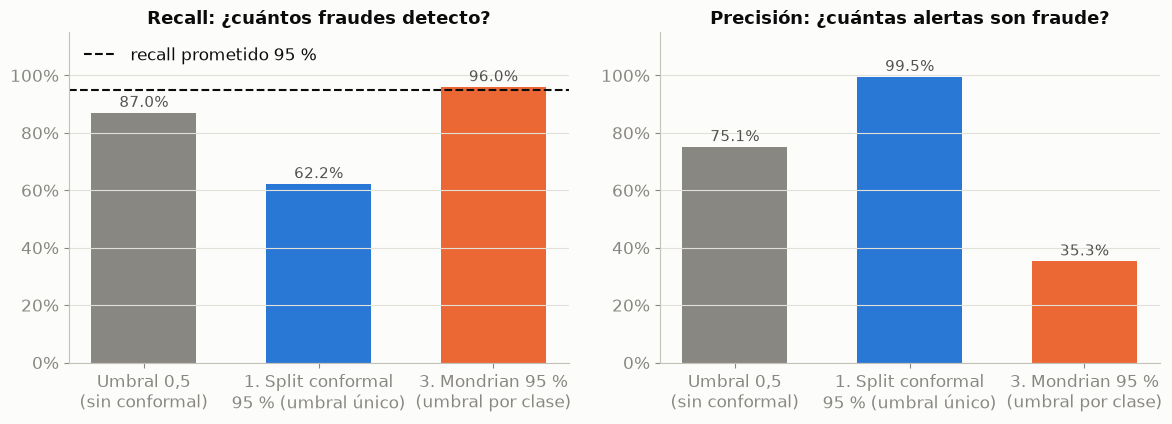

In [13]:
# =============================================================================
# B.6 Figura: recall y precisión por regla
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
colors = [MUTED, BLUE, ORANGE]
labels = ["Umbral 0,5\n(sin conformal)", "1. Split conformal\n95 % (umbral único)", "3. Mondrian 95 %\n(umbral por clase)"]
for ax, col, title in [(axes[0], "recall", "Recall: ¿cuántos fraudes detecto?"),
                       (axes[1], "precision", "Precisión: ¿cuántas alertas son fraude?")]:
    bars = ax.bar(labels, rules[col], color=colors, width=0.6)
    for r, v in zip(bars, rules[col]):
        ax.text(r.get_x() + r.get_width() / 2, v + 0.02, f"{v:.1%}", ha="center", color=INK2, fontsize=11)
    ax.set(ylim=(0, 1.15), title=title)
    ax.yaxis.set_major_formatter(pct)
    ax.grid(axis="x", visible=False)
axes[0].axhline(0.95, color=INK, ls="--", lw=1.5, label="recall prometido 95 %")
axes[0].legend(loc="upper left")
plt.tight_layout()
save("b_reglas_recall_precision.png")
plt.show()

### B.3 ¿Se cumple para cualquier nivel? ¿Cuánto cuesta en alertas?

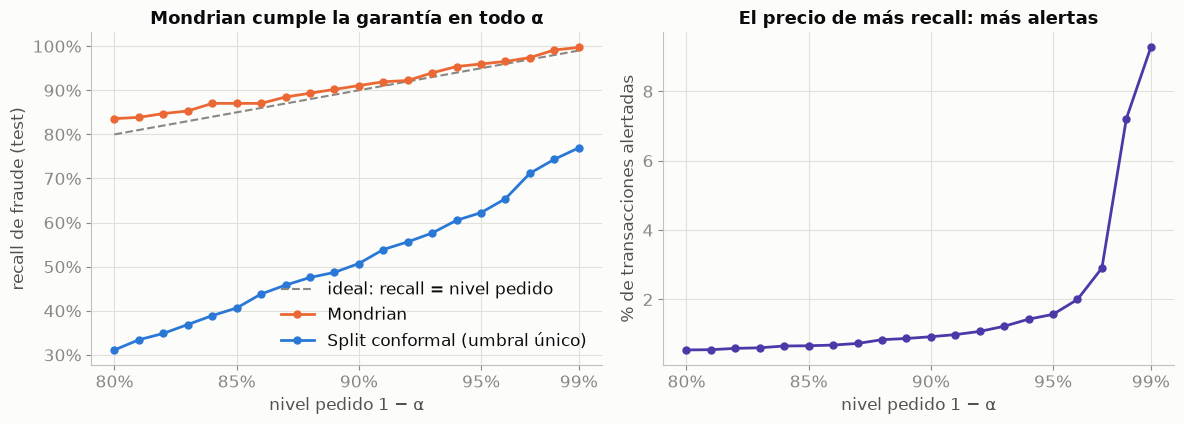

In [14]:
# =============================================================================
# B.7 Recall frente al nivel pedido y porcentaje de alertas
# =============================================================================
levels = np.linspace(0.80, 0.99, 20)
rec_mo = [sets_mondrian(P_te, 1 - l)[y_te == 1, 1].mean() for l in levels]
rec_sp = [sets_split(P_te, 1 - l)[y_te == 1, 1].mean() for l in levels]
alerts_mo = [sets_mondrian(P_te, 1 - l)[:, 1].mean() for l in levels]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(levels, levels, color=MUTED, ls="--", lw=1.5, label="ideal: recall = nivel pedido")
axes[0].plot(levels, rec_mo, color=ORANGE, lw=2, marker="o", ms=5, label="Mondrian")
axes[0].plot(levels, rec_sp, color=BLUE, lw=2, marker="o", ms=5, label="Split conformal (umbral único)")
axes[0].set(xlabel="nivel pedido 1 − α", ylabel="recall de fraude (test)", title="Mondrian cumple la garantía en todo α")
axes[0].yaxis.set_major_formatter(pct)
axes[0].legend(loc="lower right")
axes[1].plot(levels, np.array(alerts_mo) * 100, color=VIOLET, lw=2, marker="o", ms=5)
axes[1].set(xlabel="nivel pedido 1 − α", ylabel="% de transacciones alertadas", title="El precio de más recall: más alertas")
for ax in axes:
    ax.xaxis.set_major_formatter(pct)
    ax.set_xticks([0.80, 0.85, 0.90, 0.95, 0.99])
plt.tight_layout()
save("b_recall_vs_alpha.png")
plt.show()

### B.4 Prueba de fuego: meses futuros (`fraudTest.csv`), calibrados con el pasado

- **Izquierda, datos de prueba:** las 60.000 transacciones del mismo periodo que apartamos al inicio (el modelo no las usó ni para entrenar ni para calibrar).
- **Derecha, datos futuros:** las 555.719 transacciones de los meses siguientes.

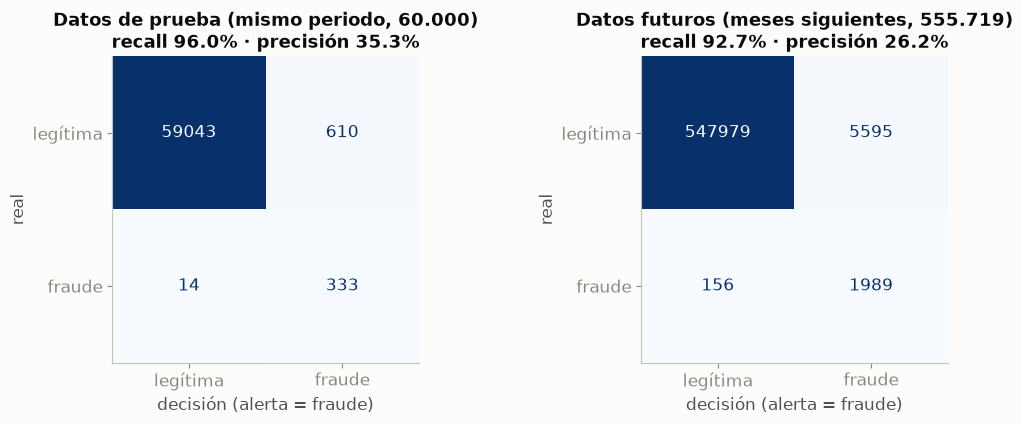

Tasa de fraude: histórica 0.58% -> futura 0.39%


,recall,precision,alertas,falsos negativos,falsos positivos
regla,,,,,
"Umbral 0,5 (sin conformal)",82.8%,64.2%,"2,766",368,989
3. Mondrian 95 %,92.7%,26.2%,"7,584",156,5595


In [15]:
# =============================================================================
# B.8 Datos futuros: matrices de confusión de Mondrian 95 %
# =============================================================================
prod = pd.read_csv(DATA_DIR / FILES["production"], usecols=COLS)
Xp, yp = features(prod), prod["is_fraud"].to_numpy()
for c in ("category", "gender"):                       # mismas categorías que en entrenamiento
    Xp[c] = pd.Categorical(Xp[c], categories=Xh[c].cat.categories)
P_prod = clf.predict_proba(Xp)
alert_prod = sets_mondrian(P_prod, ALPHA_C)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, yt, al, title in [(axes[0], y_te, S_mo[:, 1], "Datos de prueba (mismo periodo, 60.000)"),
                          (axes[1], yp, alert_prod, "Datos futuros (meses siguientes, 555.719)")]:
    ConfusionMatrixDisplay(confusion_matrix(yt, al), display_labels=["legítima", "fraude"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set(title=f"{title}\nrecall {recall_score(yt, al):.1%} · precisión {precision_score(yt, al):.1%}",
           xlabel="decisión (alerta = fraude)", ylabel="real")
    ax.grid(False)
plt.tight_layout()
save("b_matrices_confusion.png")
plt.show()

print(f"Tasa de fraude: histórica {yh.mean():.2%} -> futura {yp.mean():.2%}")
pd.DataFrame([report("Umbral 0,5 (sin conformal)", P_prod[:, 1] >= 0.5, yp),
              report("3. Mondrian 95 %", alert_prod, yp)]).set_index("regla").style.format(FMT)

**Lectura:** en los meses futuros el recall de Mondrian cae a ~92,7 %, **por debajo del 95 % prometido**. La tasa de fraude cambió:
los datos futuros **no son intercambiables** con los de calibración. No es una falla del método, es su **supuesto**:
en producción se **monitorea el recall** y se **recalibra** con datos recientes.

---
# Parte C. ¿Cuántos datos de calibración necesito?

Para un conjunto de calibración **fijo**, la cobertura que se obtiene es aleatoria y sigue una distribución
$\text{Beta}(k,\, n+1-k)$ con $k = \lceil (n+1)(1-\alpha) \rceil$ (Vovk, 2012). Lo verificamos con una simulación.

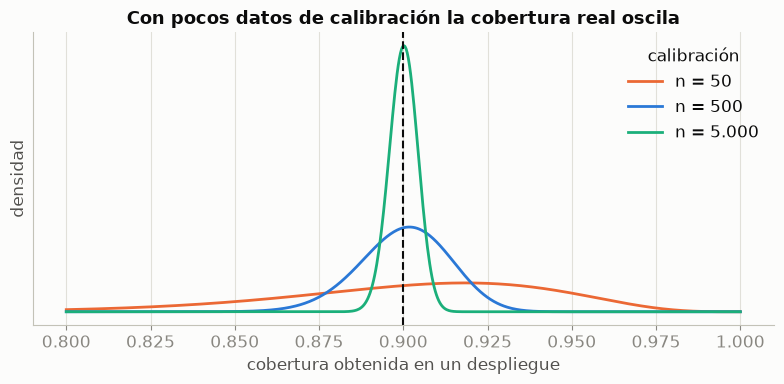

,teoría p5,teoría p95,simulación p5,simulación p95
n calibración,,,,
50,82.6%,96.0%,82.2%,95.8%
500,87.7%,92.1%,87.7%,92.1%
5000,89.3%,90.7%,89.3%,90.8%


In [16]:
# =============================================================================
# C.1 Teoría (Beta) frente a simulación
# =============================================================================
pool = rng.standard_normal(400_000) ** 2          # scores de un "modelo" cualquiera: solo importa su ranking
fig, ax = plt.subplots(figsize=(8, 4))
grid_c = np.linspace(0.8, 1.0, 600)
rows = []
for n_cal, color in [(50, ORANGE), (500, BLUE), (5000, AQUA)]:
    k = int(np.ceil((n_cal + 1) * 0.9))
    dist = stats.beta(k, n_cal + 1 - k)
    ax.plot(grid_c, dist.pdf(grid_c), color=color, lw=2, label=f"n = {n_cal:,}".replace(",", "."))
    sim = [stats.chi2.cdf(conformal_quantile(rng.choice(pool, n_cal, replace=False), 0.10), df=1) for _ in range(1000)]
    rows.append({"n calibración": n_cal, "teoría p5": dist.ppf(0.05), "teoría p95": dist.ppf(0.95),
                 "simulación p5": np.quantile(sim, 0.05), "simulación p95": np.quantile(sim, 0.95)})
ax.axvline(0.9, color=INK, ls="--", lw=1.5)
ax.set(xlabel="cobertura obtenida en un despliegue", ylabel="densidad", yticks=[],
       title="Con pocos datos de calibración la cobertura real oscila")
ax.legend(title="calibración")
plt.tight_layout()
save("c_variabilidad_calibracion.png")
plt.show()
pd.DataFrame(rows).set_index("n calibración").style.format("{:.1%}")

**Regla práctica:** con $n \approx 500$ la cobertura real de un objetivo de 90 % queda entre ~88 % y ~92 %;
con $n \approx 5.000$, entre ~89 % y ~91 %. En Mondrian la cuenta es **por clase**: la clase fraude se calibró con solo 348 casos.

---
# Parte D. Los mismos métodos con MAPIE

**MAPIE** (compatible con scikit-learn, `pip install mapie`, versión 1.x) implementa los métodos 1 y 2. Verificamos que da
**los mismos resultados** que nuestras funciones, usando los mismos modelos XGBoost ya entrenados (`prefit=True`).

| Clase de MAPIE | Método |
|---|---|
| `SplitConformalRegressor(model, confidence_level, prefit=True)` | 1. Split conformal (regresión) |
| `ConformalizedQuantileRegressor([lo, hi, mediana], confidence_level, prefit=True)` | 2. CQR |
| `SplitConformalClassifier(clf, confidence_level, conformity_score="lac", prefit=True)` | 1. Split conformal (clasificación); `"lac"` es el score $1 - \hat p$ |

Flujo común: `conformalize(X_cal, y_cal)` y luego `predict_interval(X)` o `predict_set(X)`.
El **método 3 (Mondrian por clase)** se implementa a mano con `conformal_quantile`, como en la Parte B.

In [17]:
# =============================================================================
# D.1 MAPIE frente a la implementación manual
# =============================================================================
try:
    from mapie.classification import SplitConformalClassifier
    from mapie.metrics.classification import classification_coverage_score
    from mapie.metrics.regression import regression_coverage_score, regression_mean_width_score
    from mapie.regression import ConformalizedQuantileRegressor, SplitConformalRegressor
except ImportError:
    SplitConformalRegressor = None
    print("MAPIE no está instalado: ejecute  pip install mapie  y vuelva a correr esta celda.")

if SplitConformalRegressor is not None:
    reg = SplitConformalRegressor(mean_model, confidence_level=1 - ALPHA, prefit=True)       # método 1
    reg.conformalize(X[cal], y[cal])
    _, int_split = reg.predict_interval(X[te])            # forma (n, 2, 1): [inferior, superior]

    med_m = XGBRegressor(objective="reg:quantileerror", quantile_alpha=0.5, **XGB_REG).fit(X[tr], y[tr])
    cqr = ConformalizedQuantileRegressor([lo_m, hi_m, med_m], confidence_level=1 - ALPHA, prefit=True)   # método 2
    cqr.conformalize(X[cal], y[cal])
    _, int_cqr = cqr.predict_interval(X[te])

    cls = SplitConformalClassifier(clf, confidence_level=1 - ALPHA_C, conformity_score="lac", prefit=True)
    cls.conformalize(X_cal, y_cal)
    _, sets_mapie = cls.predict_set(X_te)                 # forma (n, clases, 1), booleano

    comparison = pd.DataFrame([
        {"caso": "1. Split conformal (regresión)", "manual": cov_split,
         "MAPIE": regression_coverage_score(y[te], int_split)[0]},
        {"caso": "2. CQR (regresión)", "manual": cov_cqr, "MAPIE": regression_coverage_score(y[te], int_cqr)[0]},
        {"caso": "1. Split conformal (fraude)", "manual": S_split[np.arange(len(y_te)), y_te].mean(),
         "MAPIE": classification_coverage_score(y_te, sets_mapie)[0]},
    ]).set_index("caso")
    print("Conjuntos idénticos en clasificación:", bool((sets_mapie[:, :, 0] == S_split).all()))
    print(f"Ancho medio split: manual {2 * q_hat:.3f} | MAPIE {regression_mean_width_score(int_split)[0]:.3f}")
    display(comparison.style.format("{:.1%}"))

Conjuntos idénticos en clasificación: True
Ancho medio split: manual 7.556 | MAPIE 7.556


,manual,MAPIE
caso,,
1. Split conformal (regresión),91.5%,91.5%
2. CQR (regresión),90.4%,90.9%
1. Split conformal (fraude),95.3%,95.3%


**Lectura:** split conformal coincide exactamente. En CQR, MAPIE da una cobertura algo distinta por detalles internos de su implementación, sin cambiar la garantía.

---
## Conclusiones

1. Con **un set de calibración, un score y un cuantil**, cualquier modelo (aquí XGBoost) entrega intervalos o conjuntos con garantía.
2. **Banda fija** para empezar, **CQR** cuando el ruido cambia con x y **Mondrian** cuando una clase importa más: así se **garantiza el recall**.
3. La garantía depende de la **intercambiabilidad**: en datos futuros bajó a ~92,7 %. En producción se monitorea y se recalibra.

## Ejercicios propuestos
1. Cambie el nivel de Mondrian a 99 % y compare el recall, la precisión y el número de alertas con el 95 %.
2. Recalibre Mondrian con los **últimos** meses de la historia (orden temporal) y compare el recall en `fraudTest`.
3. Reemplace el `XGBRegressor` de la Parte A por una regresión lineal: ¿cambia la validez? ¿y el ancho?

## Referencias principales
- Angelopoulos, A. N. & Bates, S. (2023). *Conformal prediction: A gentle introduction*. Foundations and Trends in ML.
- Chen, T. & Guestrin, C. (2016). *XGBoost: A scalable tree boosting system*. KDD.
- Romano, Y., Patterson, E. & Candès, E. J. (2019). *Conformalized quantile regression*. NeurIPS.
- Vovk, V. (2012). *Conditional validity of inductive conformal predictors*. ACML.